# Baseline A: Measurement-Only Glaucoma Classifier

Question, metrics and protocol: `docs/baseline_a.md`. This notebook is the driver; heavy logic lives in `src/glaucoma_project/`.

## 0. Setup

In [1]:
import matplotlib.pyplot as plt

from glaucoma_project.data import SPLITS, SegmentationDataset
from glaucoma_project.visualization import show_overlays

datasets = {split: SegmentationDataset(split) for split in SPLITS}
{split: len(ds) for split, ds in datasets.items()}

{'train': 787, 'validation': 200, 'in_domain_test': 327, 'external_test': 486}

## 1. Data check
Expert disc (cyan) and cup (yellow) outlines drawn over a few training images per camera, and over PAPILA, the external dataset. We check that the outlines sit on the real disc and cup, and see how the cameras differ.

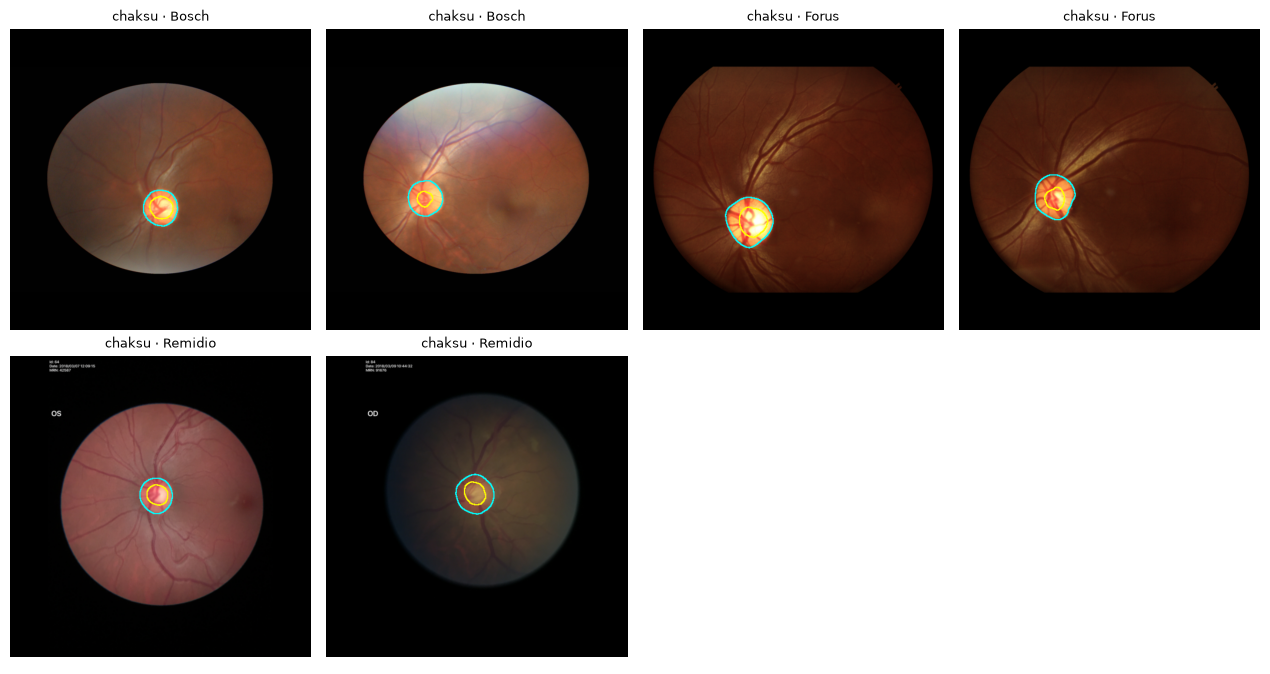

In [2]:
train = datasets['train'].table
indices = train.groupby('camera').head(2).index.tolist()
show_overlays(datasets['train'], indices);

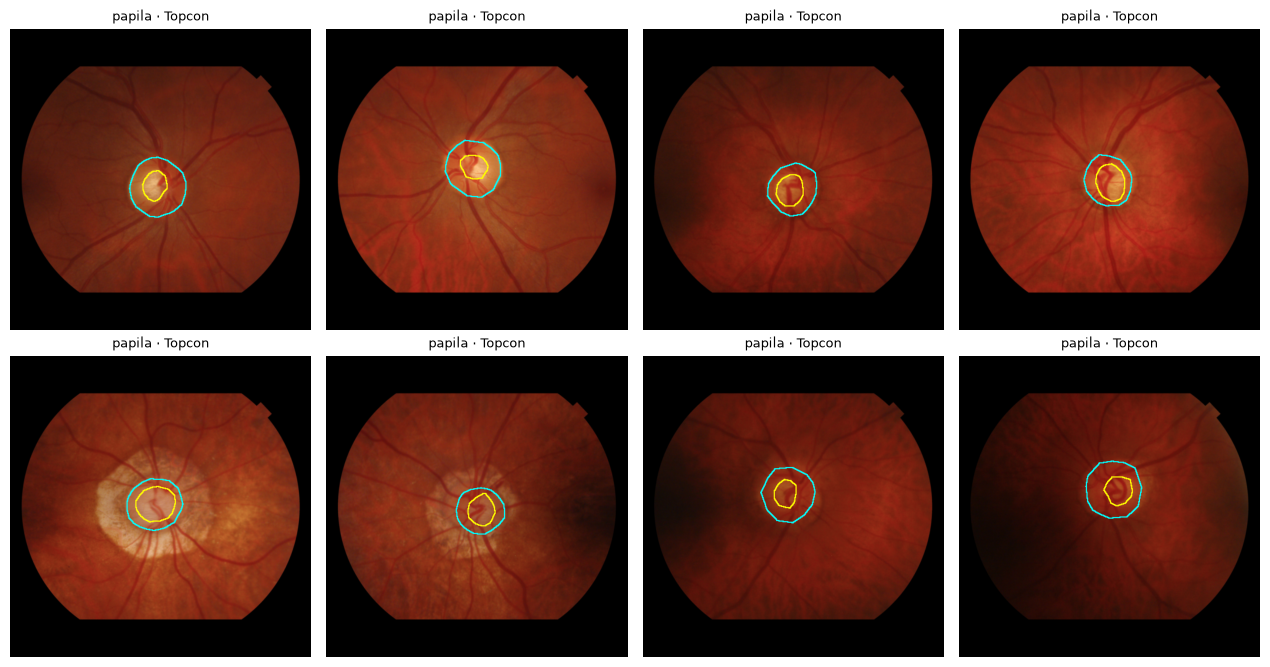

In [3]:
external = datasets['external_test']
show_overlays(external, list(range(0, 8)), ncols=4);

In [4]:
item = datasets['train'][0]
print({k: tuple(v.shape) if hasattr(v, 'shape') else v for k, v in item.items()})

{'image': (3, 512, 512), 'mask': (2, 512, 512), 'image_id': 'chaksu_Bosch_train_Image101'}


## 2. Segmentation
Train the U-Net on train, tune on validation, report Dice/IoU. *(module: `segmentation`, config: `configs/segmentation.yaml`)*

## 3. Measurements
Vertical/horizontal/area CDR and disc/cup areas from predicted masks, plus the oracle from expert masks. *(module: `measurements`)*

## 4. Classification
Logistic regression on measurements; choose threshold on validation. *(module: `classification`, config: `configs/baseline_a.yaml`)*

## 5. Final evaluation
Run once on CHAKSU test and PAPILA: AUC, sensitivity, specificity, sensitivity at 95% specificity, AUPRC, balanced accuracy, with bootstrap CIs. *(module: `evaluation`)*

## 6. Results and limitations
Summary table, ROC curves, example failures, caveats from `docs/baseline_a.md`.